# M4 — Patient-ID–stratified re-aggregation of the frozen M2 predictions

**One intervention:** report the frozen M2 out-of-fold (OOF) predictions per official NLM **Patient-ID** mapping key, alongside the pooled cell-weighted metrics. No retraining, threshold change, new data, augmentation or model change. It is an evaluation/reporting change, not a model improvement, on a public segmented-cell dataset; no clinical claim.

The pre-registered prediction and decision rule are in `milestones/M3/hypothesis.md` (recorded 3 October 2026). The ablations are exploratory (`milestones/M4/ablation_plan.md`) and do not change the primary verdict. This notebook needs only the CSVs in `results/baseline/`: no images, no GPU.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = next(parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (parent / 'src').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option('display.width', 200)
print(f'Project root: {ROOT}')

Project root: /Users/amankumar/Desktop/CV


## 1. Reuse assertions (fail loudly)
Row count, unique `relative_path`, folds/labels/Patient-IDs identical to `fold_assignments.csv`, no Patient-ID in two folds, saved prediction = `p >= 0.5`, and pooled per-fold metrics recomputed with `src.evaluation.binary_metrics` equal to `fold_results.csv` (tolerance 1e-9). Any failure raises `ReuseAssertionError`.

In [2]:
from src import patient_stratified as ps
from src.run_m4 import load_frozen_inputs

inputs = load_frozen_inputs(ROOT)
checks = ps.check_reuse(inputs['predictions'], inputs['assignments'], inputs['fold_results'], inputs['baseline_results'])
checks

{'row_count': 27558,
 'unique_relative_path': True,
 'identical_to_fold_assignments': ['filename',
  'class_name',
  'label',
  'patient_id',
  'fold'],
 'patient_ids_in_one_fold': 201,
 'prediction_equals_threshold_0_5': True,
 'pooled_metrics_equal_fold_results': {'tolerance': 1e-09,
  'max_abs_difference': np.float64(1.1102230246251565e-16)},
 'fold_mean_sd_equal_baseline_results': True}

## 2. Per-Patient-ID metrics
Sensitivity/FNR are defined only for IDs with Parasitized cells, specificity only for IDs with Uninfected cells. Undefined values stay `NaN` with an explicit flag; no ID is dropped.

In [3]:
patients = ps.per_patient_metrics(inputs['predictions'])
print('Patient-IDs:', patients.patient_id.nunique(),
      '| with Parasitized cells:', int(patients.sensitivity_defined.sum()),
      '| Uninfected only:', int((~patients.sensitivity_defined).sum()))
display(patients.head(8))

Patient-IDs: 201 | with Parasitized cells: 151 | Uninfected only: 50


,fold,patient_id,n_cells,n_positive,n_negative,tp,fn,tn,fp,n_correct,n_errors,accuracy,sensitivity_defined,sensitivity,false_negative_rate,specificity_defined,specificity,false_positive_rate,mean_probability
0,1,C103P64ThinF,107,39,68,38,1,60,8,98,9,0.915888,True,0.974359,0.025641,True,0.882353,0.117647,0.448995
1,1,C105P66ThinF,85,17,68,15,2,67,1,82,3,0.964706,True,0.882353,0.117647,True,0.985294,0.014706,0.201533
2,1,C110P71ThinF,93,24,69,20,4,66,3,86,7,0.924731,True,0.833333,0.166667,True,0.956522,0.043478,0.254314
3,1,C115P76ThinF,78,13,65,7,6,58,7,65,13,0.833333,True,0.538462,0.461538,True,0.892308,0.107692,0.202181
4,1,C118P79ThinF,353,283,70,274,9,63,7,337,16,0.954674,True,0.968198,0.031802,True,0.900000,0.100000,0.786914
5,1,C128P89ThinF,206,136,70,126,10,65,5,191,15,0.927184,True,0.926471,0.073529,True,0.928571,0.071429,0.642942
6,1,C136P97ThinF,397,327,70,314,13,62,8,376,21,0.947103,True,0.960245,0.039755,True,0.885714,0.114286,0.803241
7,1,C137P98ThinF,408,332,76,328,4,70,6,398,10,0.975490,True,0.987952,0.012048,True,0.921053,0.078947,0.811477


## 3. Pooled vs Patient-ID-macro metrics per fold

In [4]:
folds = ps.fold_metrics(inputs['predictions'], patients)
columns = ['fold', 'n_ids_total', 'n_ids_sensitivity', 'n_ids_sensitivity_undefined',
           'pooled_sensitivity_recall', 'macro_sensitivity', 'pooled_specificity', 'macro_specificity',
           'pooled_accuracy', 'macro_accuracy', 'id_sensitivity_sd', 'id_false_negative_rate_iqr']
display(folds[columns].round(4))

,fold,n_ids_total,n_ids_sensitivity,n_ids_sensitivity_undefined,pooled_sensitivity_recall,macro_sensitivity,pooled_specificity,macro_specificity,pooled_accuracy,macro_accuracy,id_sensitivity_sd,id_false_negative_rate_iqr
0,1,40,30,10,0.9531,0.9115,0.9206,0.9210,0.9369,0.9287,0.1338,0.0966
1,2,40,30,10,0.8828,0.8972,0.9301,0.9300,0.9063,0.9213,0.1331,0.1372
2,3,41,31,10,0.9638,0.9555,0.9352,0.9358,0.9493,0.9445,0.0603,0.0788
3,4,40,31,9,0.9552,0.9397,0.9562,0.9561,0.9557,0.9563,0.0754,0.0901
4,5,40,29,11,0.9571,0.9299,0.9361,0.9356,0.9467,0.9426,0.0871,0.1000


## 4. Primary result and the M3 verdict
SUPPORTED if at least 4 of 5 paired differences (macro − pooled sensitivity) are negative **and** the mean is ≤ −1.68 pp; UNSUPPORTED is the mirror rule; otherwise INCONCLUSIVE. With n = 5, no significance test is claimed (the smallest two-sided exact Wilcoxon p is 0.0625).

In [5]:
primary = ps.paired_differences(folds, 'sensitivity')
verdict = ps.decide_verdict(primary.difference_pp)
display(primary.round(4))
print(json.dumps(verdict, indent=2))
print('t-interval for the mean (pp):', {k: round(v, 3) for k, v in ps.t_interval(primary.difference_pp).items()})

,fold,metric,n_ids_eligible,pooled,macro,difference,difference_pp,direction
0,1,sensitivity,30,0.9531,0.9115,-0.0416,-4.1644,negative
1,2,sensitivity,30,0.8828,0.8972,0.0145,1.4488,positive
2,3,sensitivity,31,0.9638,0.9555,-0.0083,-0.8287,negative
3,4,sensitivity,31,0.9552,0.9397,-0.0155,-1.5531,negative
4,5,sensitivity,29,0.9571,0.9299,-0.0272,-2.7221,negative


{
  "verdict": "INCONCLUSIVE",
  "n_folds": 5,
  "n_negative": 4,
  "n_positive": 1,
  "mean_difference_pp": -1.5639072002236665,
  "threshold_pp": 1.68,
  "supported_rule_met": false,
  "unsupported_rule_met": false,
  "reasons": [
    "|mean| 1.564 pp < 1.68 pp",
    "direction negative but magnitude below the threshold"
  ]
}
t-interval for the mean (pp): {'mean': -1.564, 'sd': 2.105, 'low': -4.177, 'high': 1.05, 'df': 4}


## 5. Full run: writes `results/m4/` (verdict JSON, ablations, figures)
`run_m4` repeats the steps above, then computes the exploratory ablations A1–A5 and saves every table and figure. The verdict printed above must equal the saved one.

In [6]:
from src.run_m4 import run_m4

result = run_m4(ROOT)
saved = json.loads((ROOT / 'results/m4/primary_verdict.json').read_text())
assert saved['verdict'] == verdict['verdict']
assert abs(saved['mean_difference_pp'] - verdict['mean_difference_pp']) < 1e-12
{key: saved[key] for key in ['verdict', 'n_negative', 'n_positive', 'mean_difference_pp',
                             'mean_within_predicted_range', 'verdict_under_exact_threshold',
                             't_interval_95_pp', 'bootstrap_95_pp_exploratory_a4']}

{'verdict': 'INCONCLUSIVE',
 'n_negative': 4,
 'n_positive': 1,
 'mean_difference_pp': -1.5639072002236665,
 'mean_within_predicted_range': True,
 'verdict_under_exact_threshold': 'INCONCLUSIVE',
 't_interval_95_pp': {'mean': -1.5639072002236665,
  'sd': 2.104814111310206,
  'low': -4.1773791051488,
  'high': 1.0495647047014667,
  'df': 4},
 'bootstrap_95_pp_exploratory_a4': {'ci_low_pp': -2.9487875820335687,
  'ci_high_pp': -0.035100255117505835,
  'n_resamples': 2000,
  'seed': 42}}

## 6. Exploratory ablations (aggregation only; they do not change the verdict)

In [7]:
ablations = ROOT / 'results/m4/ablations'
for name in ['a1_weighting', 'a2_summary', 'a3_summary', 'a4_bootstrap', 'a5_secondary_metrics']:
    print(f'--- {name}')
    display(pd.read_csv(ablations / f'{name}.csv').round(4))

--- a1_weighting


,fold,n_ids_with_positive_cells,pooled_cell_weighted,patient_id_macro,per_id_weighted_by_positive_cells,weighted_minus_pooled,macro_minus_pooled_pp
0,1,30,0.9531,0.9115,0.9531,0.0,-4.1644
1,2,30,0.8828,0.8972,0.8828,0.0,1.4488
2,3,31,0.9638,0.9555,0.9638,0.0,-0.8287
3,4,31,0.9552,0.9397,0.9552,0.0,-1.5531
4,5,29,0.9571,0.9299,0.9571,0.0,-2.7221


--- a2_summary


,min_positive_cells,mean_pp,sd_pp,n_negative,n_positive,ids_kept,ids_excluded,share_positive_cells_kept
0,1,-1.5639,2.1048,4,1,151,0,1.0000
1,10,-1.9978,2.7190,4,1,121,30,0.9887
2,25,-1.2840,1.2610,4,1,84,67,0.9453


--- a3_summary


,fold,n_deletions,observed_difference_pp,min_difference_pp_without,max_difference_pp_without,max_abs_change_pp,most_influential_patient_id,most_influential_n_positive,most_influential_sensitivity,deletions_changing_verdict
0,1,30,-4.1644,-4.4645,-3.0750,1.0895,C115P76ThinF,13,0.5385,0
1,2,30,1.4488,-0.7322,2.8944,2.1809,C116P77ThinF,414,0.7246,1
2,3,31,-0.8287,-1.0222,-0.2064,0.6223,C47P8thin_Original_Motic,8,0.7500,0
3,4,31,-1.5531,-1.9535,-1.0501,0.5030,C164P125ThinF,28,0.7143,0
4,5,29,-2.7221,-3.7230,-1.8134,1.0009,C182P143NThinF,546,0.9139,1


--- a4_bootstrap


,metric,fold,observed_difference_pp,bootstrap_mean_pp,bootstrap_se_pp,ci_low_pp,ci_high_pp,share_resamples_below_zero,n_valid_resamples,n_resamples,seed
0,sensitivity,1,-4.1644,-3.9621,1.7592,-7.5817,-0.9313,0.9945,2000,2000,42
1,sensitivity,2,1.4488,1.3026,2.6989,-3.8140,6.6840,0.3255,2000,2000,42
2,sensitivity,3,-0.8287,-0.7133,1.0577,-2.7212,1.4826,0.7625,2000,2000,42
3,sensitivity,4,-1.5531,-1.5266,1.1198,-3.7917,0.5845,0.9240,2000,2000,42
4,sensitivity,5,-2.7221,-2.6839,1.5186,-5.9125,0.0780,0.9680,2000,2000,42
5,sensitivity,mean,-1.5639,-1.5166,0.7641,-2.9488,-0.0351,0.9790,2000,2000,42
6,specificity,1,0.0409,0.0391,0.0160,0.0098,0.0722,0.0025,2000,2000,42
7,specificity,2,-0.0156,-0.0152,0.0465,-0.1177,0.0645,0.5975,2000,2000,42
8,specificity,3,0.0617,0.0595,0.0726,-0.0437,0.2255,0.2575,2000,2000,42
9,specificity,4,-0.0044,-0.0043,0.0108,-0.0247,0.0165,0.6415,2000,2000,42


--- a5_secondary_metrics


,metric,fold,n_ids_eligible,pooled,macro,difference_pp,ci_low_pp,ci_high_pp,id_sd,id_iqr,id_min,id_max
0,specificity,1,40,0.9206,0.9210,0.0409,0.0098,0.0722,0.0783,0.0597,0.5942,1.0
1,specificity,2,40,0.9301,0.9300,-0.0156,-0.1177,0.0645,0.1181,0.0582,0.3433,1.0
2,specificity,3,41,0.9352,0.9358,0.0617,-0.0437,0.2255,0.1056,0.0578,0.4559,1.0
3,specificity,4,40,0.9562,0.9561,-0.0044,-0.0247,0.0165,0.0474,0.0437,0.8235,1.0
4,specificity,5,40,0.9361,0.9356,-0.0435,-0.1022,0.0007,0.0823,0.0332,0.5882,1.0
5,specificity,mean,201,0.9356,0.9357,0.0078,-0.0256,0.0466,NaN,NaN,NaN,NaN
6,accuracy,1,40,0.9369,0.9287,-0.8204,-1.8641,0.0337,0.0670,0.0467,0.6267,1.0
7,accuracy,2,40,0.9063,0.9213,1.4934,-0.3686,3.5905,0.0925,0.0698,0.5054,1.0
8,accuracy,3,41,0.9493,0.9445,-0.4786,-1.9544,0.6561,0.0841,0.0456,0.4559,1.0
9,accuracy,4,40,0.9557,0.9563,0.0578,-0.7104,0.7754,0.0362,0.0542,0.8421,1.0


In [8]:
a3 = pd.read_csv(ablations / 'a3_leave_one_id_out.csv')
print('single-ID deletions that would change the verdict:')
display(a3[a3.verdict_changes][['fold', 'removed_patient_id', 'removed_n_positive', 'removed_sensitivity',
                                 'difference_pp_without', 'mean_difference_pp_if_removed', 'verdict_if_removed']].round(3))

single-ID deletions that would change the verdict:


,fold,removed_patient_id,removed_n_positive,removed_sensitivity,difference_pp_without,mean_difference_pp_if_removed,verdict_if_removed
33,2,C116P77ThinF,414,0.725,-0.732,-2.000,SUPPORTED
141,5,C182P143NThinF,546,0.914,-3.723,-1.764,SUPPORTED


## 7. Figures

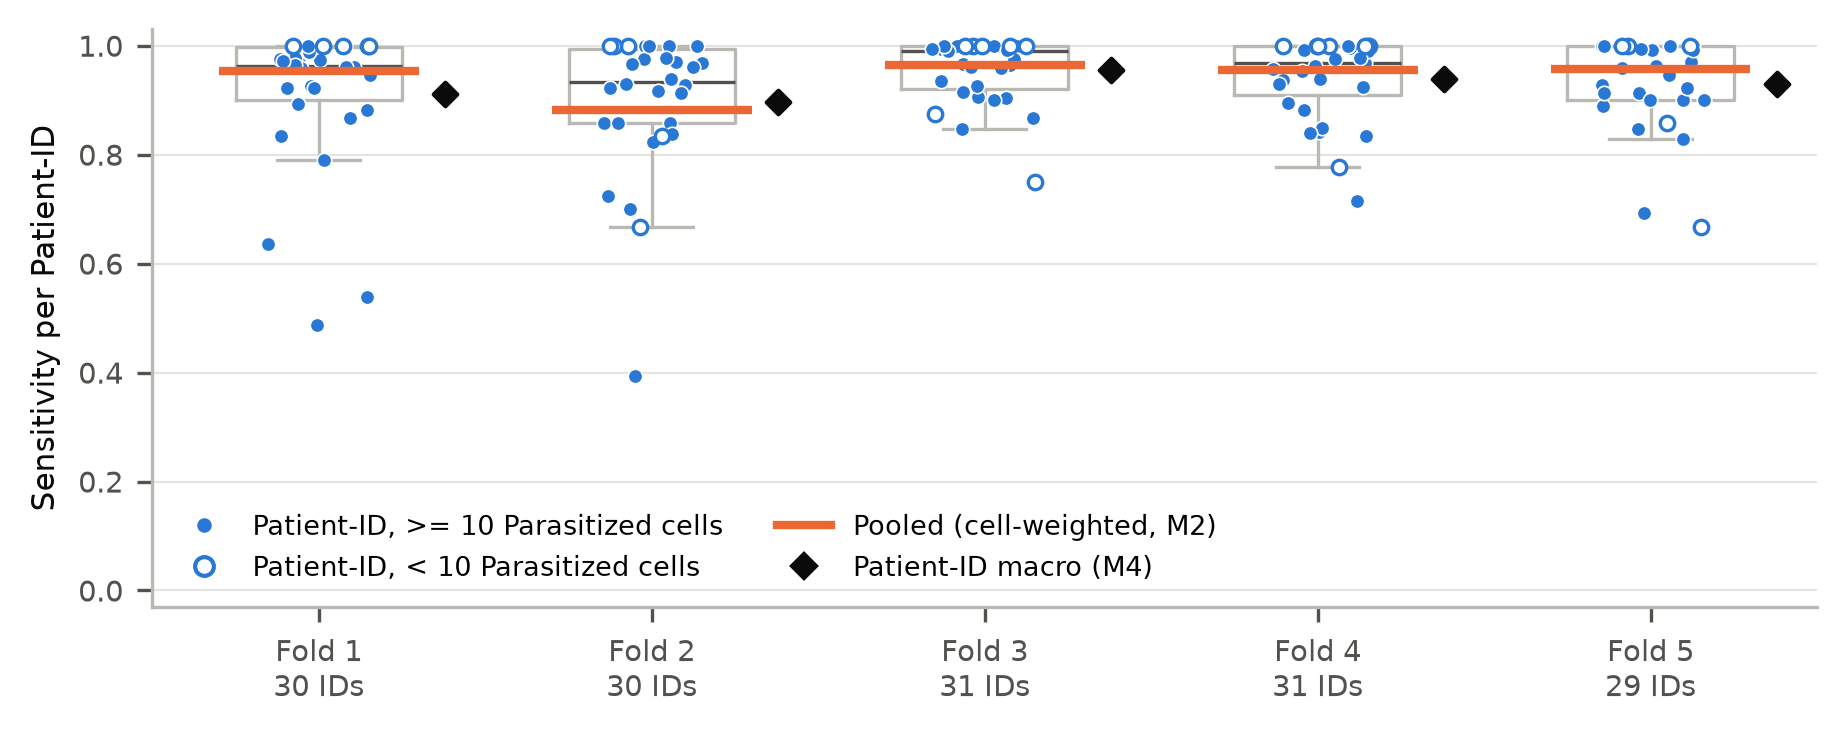

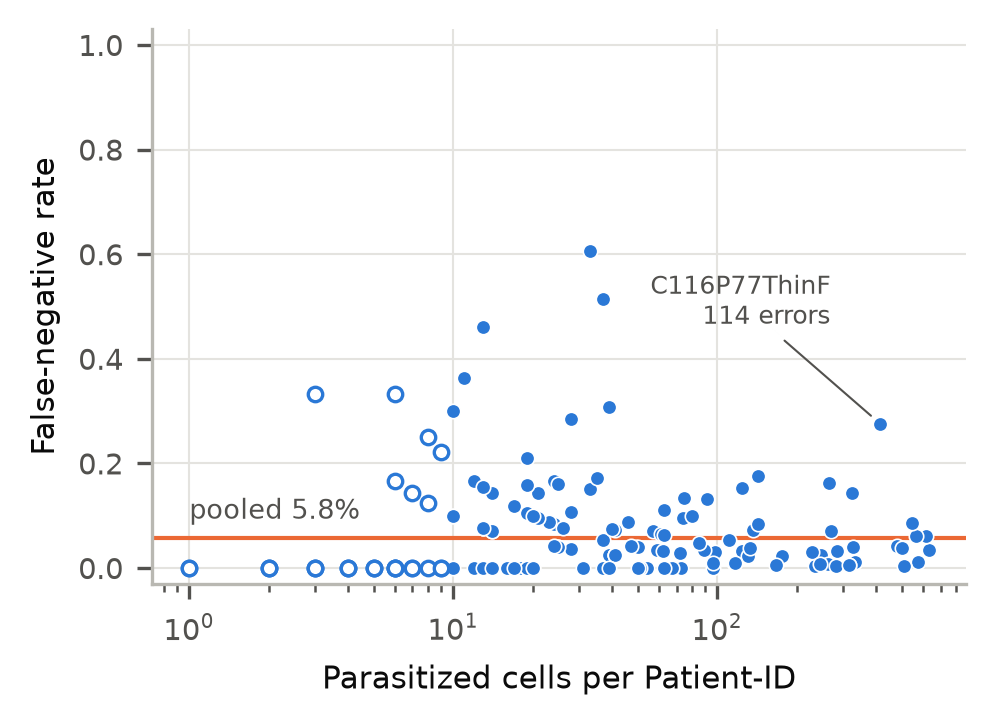

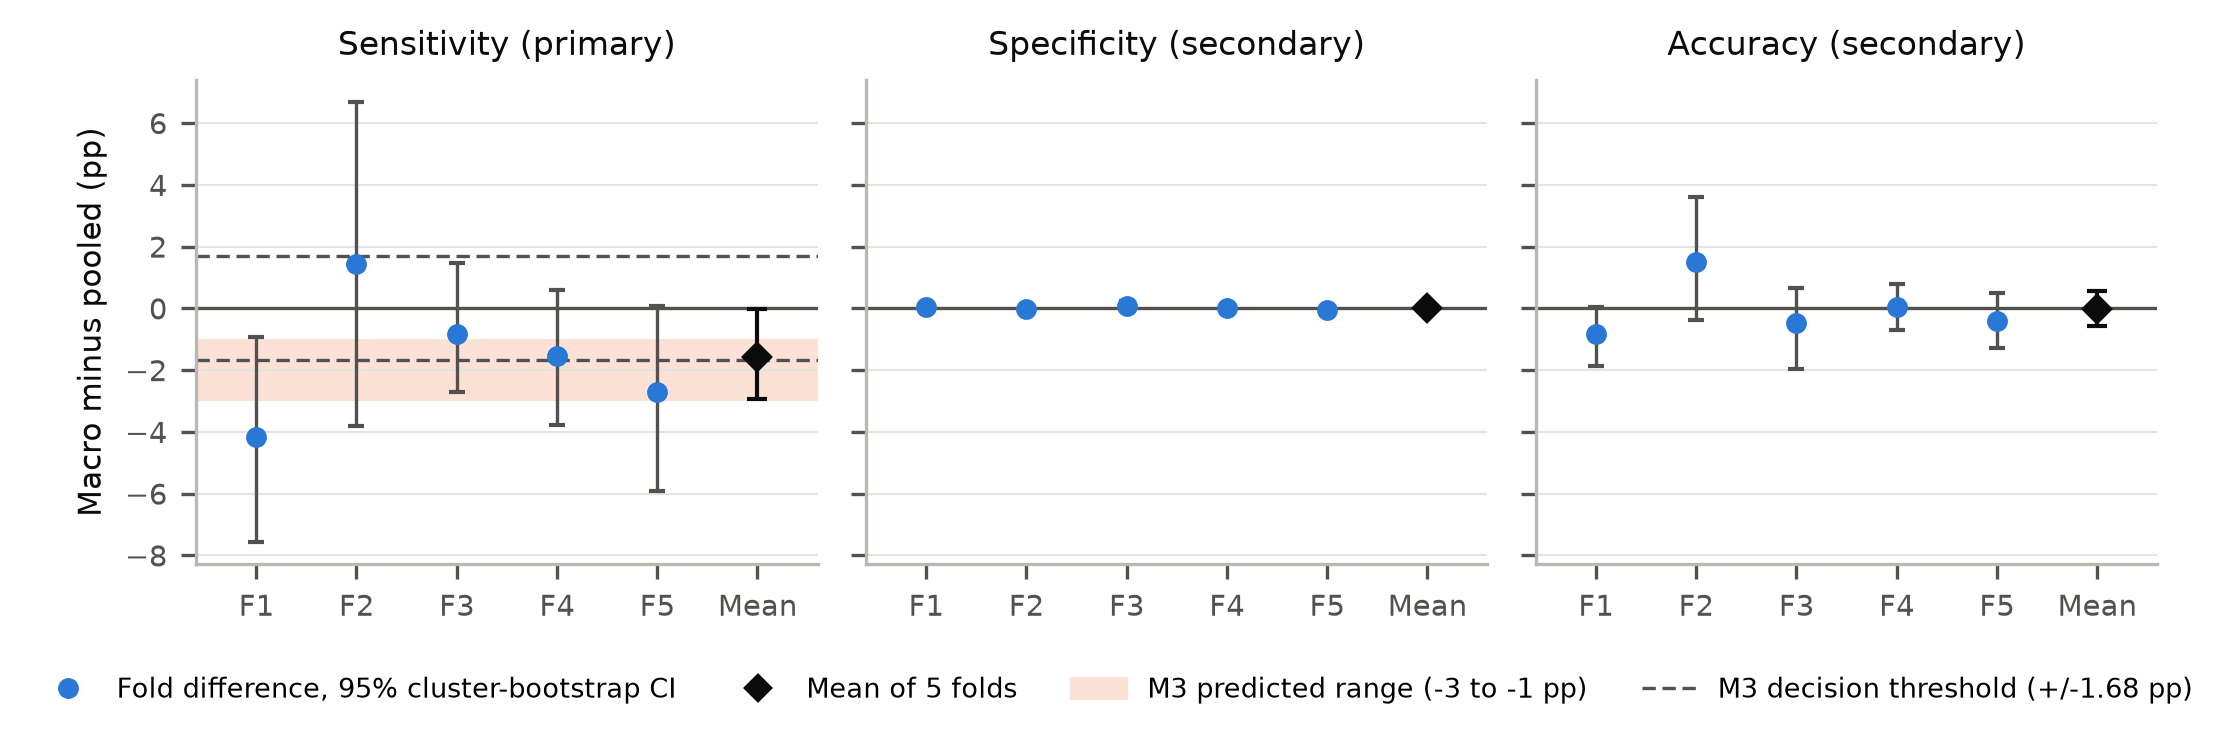

In [9]:
for name in ['per_id_sensitivity_by_fold', 'fnr_vs_positive_cells', 'paired_differences']:
    display(Image(filename=str(ROOT / 'results/m4/figures' / f'{name}.png'), width=900 if name != 'fnr_vs_positive_cells' else 500))

## 8. Reading the result

In [10]:
band = saved['pre_registration']['predicted_mean_difference_pp']
print(f"Direction: {saved['n_negative']} of {saved['n_folds']} folds negative, {saved['n_positive']} positive.")
print(f"Mean macro - pooled: {saved['mean_difference_pp']:+.2f} pp "
      f"({'inside' if saved['mean_within_predicted_range'] else 'outside'} the predicted {band[0]:g} to {band[1]:g} pp).")
print(f"Threshold as written: {saved['threshold_as_written_pp']} pp -> verdict {saved['verdict']}; "
      f"exact half-SD threshold {saved['threshold_exact_half_m2_sd_pp']:.3f} pp -> {saved['verdict_under_exact_threshold']}.")
flips = a3[a3.verdict_changes]
print(f"Single-ID deletions that would flip the verdict (exploratory A3): {len(flips)} of {len(a3)}.")

Direction: 4 of 5 folds negative, 1 positive.
Mean macro - pooled: -1.56 pp (inside the predicted -3 to -1 pp).
Threshold as written: 1.68 pp -> verdict INCONCLUSIVE; exact half-SD threshold 1.679 pp -> INCONCLUSIVE.
Single-ID deletions that would flip the verdict (exploratory A3): 2 of 151.


The decision is the M3 rule applied as written. Ablation fragility is reported, not used to change the verdict. The full write-up is in `milestones/M4/README.md`, the failure analysis in `milestones/M5/failure_analysis.md`, and the paper in `paper/main.pdf`.

**Limitations:** five folds from one seed; Patient-ID is the official mapping key, not a slide; an approximate reproduction of paper1; one public segmented-cell dataset; no clinical claim.